# Predicting Bus Delays for Reliable Public Bus Schedules

## Mission and use case
**Mission:** African cities are urbanizing fast and many people depend on public buses, but there are no public bus schedules, so trips are uncertain. My mission is a platform that publishes precise bus schedules.

**Use case:** A published timetable is only useful if it accounts for delays. This model predicts **how many minutes a bus will be delayed** (`Min Delay`) from the route, time of day, day of week, direction, and type of incident. The schedule platform uses that prediction to publish adjusted arrival times.

**Who uses the prediction and for what:**
- **Commuters** use the adjusted arrival times to plan their trips and decide when to leave.
- **Bus operators and city transport planners** see which routes, hours and incident types cause the longest delays, so they can add buffer time or spare buses.

## Dataset
**TTC Bus Delay Data** (Toronto Transit Commission), City of Toronto Open Data: https://open.toronto.ca/dataset/ttc-bus-delay-data/

Each row is one logged bus delay incident from **January 2025 to September 2026**. African cities do not yet publish bus delay logs like this one, which is the gap my platform is meant to close. This model is the prototype that would run on the same kind of data once the platform collects it from African bus operators.

| Column | Type | Meaning |
|---|---|---|
| Date | date | Day of the incident |
| Line | categorical | Bus route (number and name) |
| Time | time | Time of the incident (HH:MM) |
| Day | categorical | Day of the week |
| Station | categorical | Location of the incident |
| Code | categorical | Incident type code (see `incident_codes.csv`) |
| **Min Delay** | numeric | **Target:** delay in minutes against the schedule |
| Min Gap | numeric | Minutes between this bus and the bus ahead of it |
| Bound | categorical | Direction (N, S, E, W) |
| Vehicle | numeric | Vehicle (bus) number |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("ttc_bus_delay.csv")
codes = pd.read_csv("incident_codes.csv")

df = df.drop(columns=["_id"])  # row index added by the open data portal, not a feature
print("Shape:", df.shape)
df.head()

Shape: (107349, 10)


,Date,Line,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Vehicle
0,2025-01-01T00:00:00,102 MARKHAM ROAD,02:15,Wednesday,WARDEN STATION,MFESA,20,40,N,3442
1,2025-01-01T00:00:00,65 PARLIAMENT,02:15,Wednesday,KIPLING STATION,MFUS,0,0,NaN,0
2,2025-01-01T00:00:00,64 MAIN,02:40,Wednesday,BROADVIEW STATION,MFUI,0,0,NaN,8546
3,2025-01-01T00:00:00,100 FLEMINGDON PARK,02:43,Wednesday,OVERLEA AND THORNCLIFF,MFSAN,17,32,N,8693
4,2025-01-01T00:00:00,34 EGLINTON EAST,03:05,Wednesday,EGLINTON AND DON MILLS,MFUI,20,40,W,8801


In [3]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 107349 entries, 0 to 107348
Data columns (total 10 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   Date       107349 non-null  str  
 1   Line       106035 non-null  str  
 2   Time       107349 non-null  str  
 3   Day        107349 non-null  str  
 4   Station    107349 non-null  str  
 5   Code       107349 non-null  str  
 6   Min Delay  107349 non-null  int64
 7   Min Gap    107349 non-null  int64
 8   Bound      84443 non-null   str  
 9   Vehicle    107349 non-null  int64
dtypes: int64(3), str(7)
memory usage: 8.2 MB

Missing values per column:
Date             0
Line          1314
Time             0
Day              0
Station          0
Code             0
Min Delay        0
Min Gap          0
Bound        22906
Vehicle          0
dtype: int64


In [4]:
print("Unique values per column:")
print(df.nunique())
print("\nTarget (Min Delay) summary:")
df["Min Delay"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

Unique values per column:
Date           638
Line           695
Time          1440
Day              7
Station      17018
Code            75
Min Delay      698
Min Gap        741
Bound           17
Vehicle       2787
dtype: int64

Target (Min Delay) summary:


count    107349.000000
mean         21.505687
std          54.632735
min           0.000000
25%           8.000000
50%          12.000000
75%          20.000000
90%          30.000000
99%         261.000000
max         999.000000
Name: Min Delay, dtype: float64

## 1. Exploring the data

To explore numeric relationships, I extract a few helper columns from the raw text and date fields:
- `hour` from `Time`
- `day_of_week` (0 = Monday) and `month` from `Date`
- `route_number` from `Line` (for example `"102 MARKHAM ROAD"` becomes `102`)

The full cleaning and feature engineering happens in Section 2. These columns are only for exploration.

In [5]:
eda = df.copy()
eda["Date"] = pd.to_datetime(eda["Date"])
eda["hour"] = pd.to_datetime(eda["Time"], format="%H:%M").dt.hour
eda["day_of_week"] = eda["Date"].dt.day_of_week
eda["month"] = eda["Date"].dt.month
eda["route_number"] = pd.to_numeric(eda["Line"].str.extract(r"^(\d+)")[0], errors="coerce")
eda[["Line", "route_number", "Time", "hour", "Date", "day_of_week", "month"]].head()

,Line,route_number,Time,hour,Date,day_of_week,month
0,102 MARKHAM ROAD,102.0,02:15,2,2025-01-01,2,1
1,65 PARLIAMENT,65.0,02:15,2,2025-01-01,2,1
2,64 MAIN,64.0,02:40,2,2025-01-01,2,1
3,100 FLEMINGDON PARK,100.0,02:43,2,2025-01-01,2,1
4,34 EGLINTON EAST,34.0,03:05,3,2025-01-01,2,1


### Plot 1: Distribution of the target (`Min Delay`)

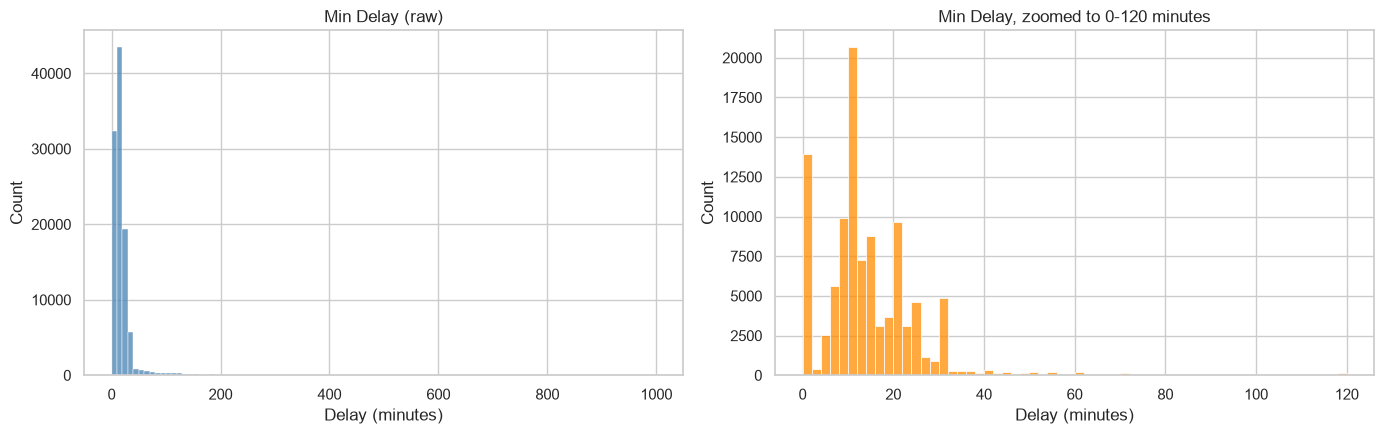

Share of rows with 0-minute delay: 12.8%
Share of rows above 120 minutes:   2.2%


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(eda["Min Delay"], bins=100, ax=axes[0], color="steelblue")
axes[0].set_title("Min Delay (raw)")
axes[0].set_xlabel("Delay (minutes)")

sns.histplot(eda.loc[eda["Min Delay"] <= 120, "Min Delay"], bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("Min Delay, zoomed to 0-120 minutes")
axes[1].set_xlabel("Delay (minutes)")

plt.tight_layout()
plt.show()

print(f"Share of rows with 0-minute delay: {(eda['Min Delay'] == 0).mean():.1%}")
print(f"Share of rows above 120 minutes:   {(eda['Min Delay'] > 120).mean():.1%}")

**What it shows:** The target is strongly right-skewed. Most delays are between 0 and 30 minutes (median 12, 90th percentile 30), 12.8% of incidents have a 0-minute delay, and a long tail reaches 999 minutes. Only about 2% of rows are above 120 minutes, and values like 999 look like placeholder entries rather than real delays.

**Decision:** In cleaning I will remove extreme outliers (very long delays) so that a few rare, multi-hour disruptions do not dominate the squared-error loss, because MSE punishes large errors heavily. The model will target everyday delays, which are what a published schedule needs to adjust for.

### Plot 2: Correlation heatmap of the numeric columns

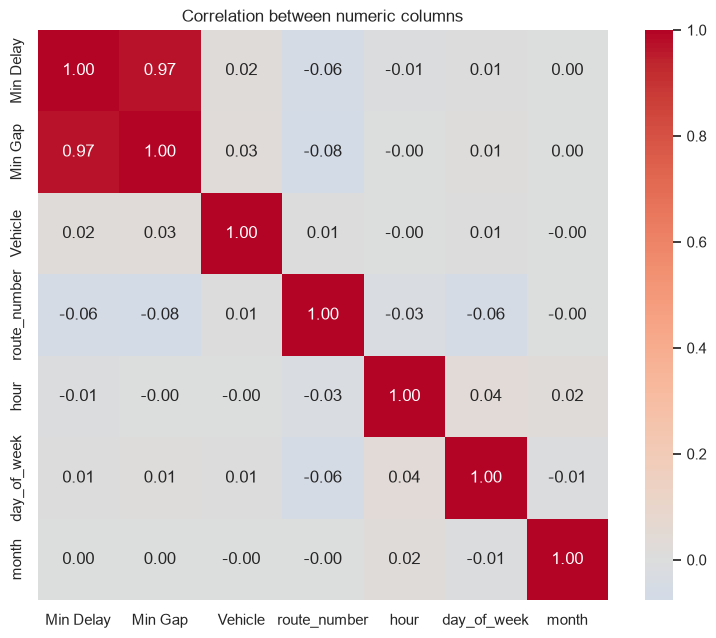

Min Gap         0.969015
route_number   -0.055661
Vehicle         0.019560
hour           -0.010884
day_of_week     0.006873
month           0.003126
Name: Min Delay, dtype: float64

In [7]:
num_cols = ["Min Delay", "Min Gap", "Vehicle", "route_number", "hour", "day_of_week", "month"]
corr = eda[num_cols].corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.show()

corr["Min Delay"].drop("Min Delay").sort_values(key=abs, ascending=False)

**What it shows:** `Min Gap` is almost perfectly correlated with the target (0.97). Every other numeric column (`Vehicle`, `route_number`, `hour`, `day_of_week`, `month`) has a correlation close to 0 with `Min Delay`, so none of them has a strong *linear* relationship with delay on its own.

**Decision:** `Min Gap` is too good to be a fair feature, so Plot 3 checks it for leakage. Because the remaining numeric columns are weak linear predictors, the categorical columns (incident type, route, direction) will have to carry most of the signal, so they must be encoded carefully. I also expect tree-based models to beat the linear ones, since they can capture non-linear effects such as particular hours or routes.

### Plot 3: `Min Gap` vs `Min Delay` (checking for leakage)

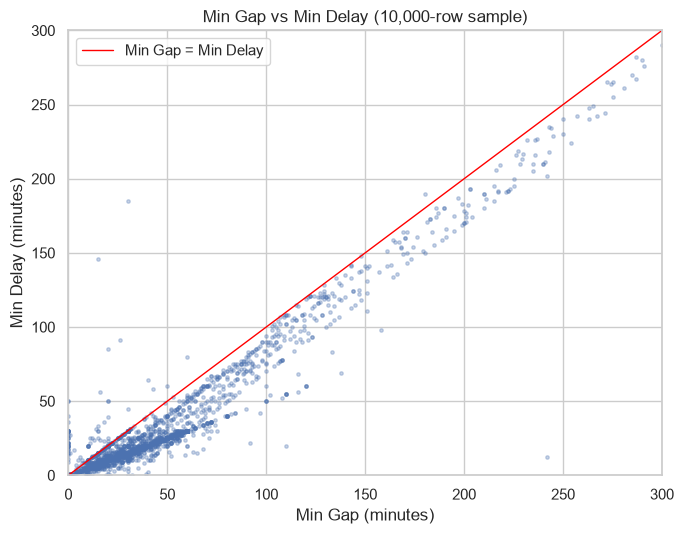

Rows where Min Gap >= Min Delay: 99.3%


In [8]:
sample = eda.sample(10_000, random_state=RANDOM_STATE)

plt.figure(figsize=(7, 5.5))
plt.scatter(sample["Min Gap"], sample["Min Delay"], s=6, alpha=0.3)
lim = 300
plt.plot([0, lim], [0, lim], color="red", lw=1, label="Min Gap = Min Delay")
plt.xlim(0, lim); plt.ylim(0, lim)
plt.xlabel("Min Gap (minutes)")
plt.ylabel("Min Delay (minutes)")
plt.title("Min Gap vs Min Delay (10,000-row sample)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Rows where Min Gap >= Min Delay: {(eda['Min Gap'] >= eda['Min Delay']).mean():.1%}")

**What it shows:** Almost every point lies on or just below the line `Min Gap = Min Delay`. In 99.3% of rows the gap is at least the delay, because the gap is the scheduled gap plus the delay itself. `Min Gap` is only known *after* the delay has happened.

**Decision:** I drop `Min Gap`. Keeping it would leak the answer into the inputs: the model would look excellent in the notebook but be useless in the app, where we want to predict the delay *before* it is known. Dropping it lowers the scores but makes the model honest.

### Plot 4: How the categorical columns affect the delay

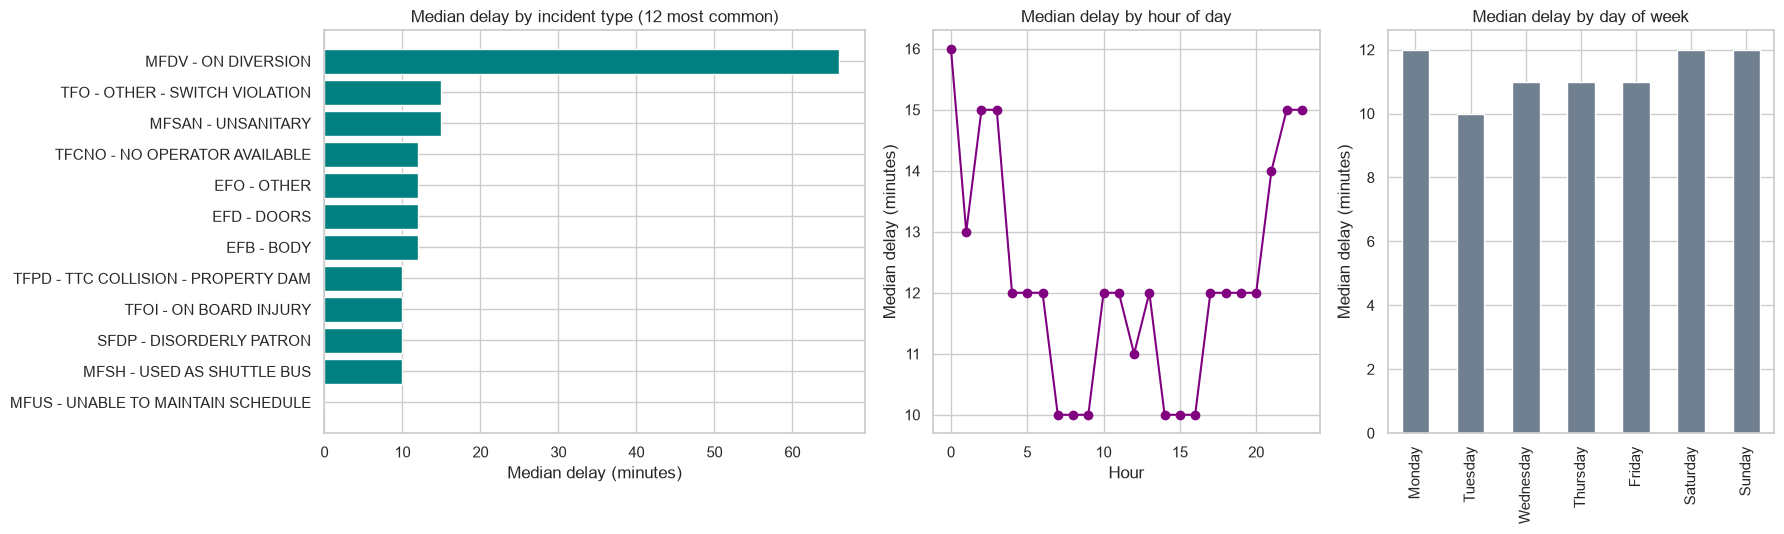

In [9]:
# the descriptions file stores some dashes as broken characters, so replace any non-ASCII run with "-"
codes["DESCRIPTION"] = codes["DESCRIPTION"].str.replace(r"[^\x20-\x7E]+", "-", regex=True)
code_desc = dict(zip(codes["CODE"], codes["DESCRIPTION"]))
top_codes = eda["Code"].value_counts().head(12).index

by_code = (eda[eda["Code"].isin(top_codes)]
           .groupby("Code")["Min Delay"].median()
           .sort_values())
labels = [f"{c} - {code_desc.get(c, 'unknown')[:28]}" for c in by_code.index]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.4, 1, 1]})

axes[0].barh(labels, by_code.values, color="teal")
axes[0].set_title("Median delay by incident type (12 most common)")
axes[0].set_xlabel("Median delay (minutes)")

eda.groupby("hour")["Min Delay"].median().plot(ax=axes[1], marker="o", color="purple")
axes[1].set_title("Median delay by hour of day")
axes[1].set_xlabel("Hour"); axes[1].set_ylabel("Median delay (minutes)")

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
eda.groupby("Day")["Min Delay"].median().reindex(day_order).plot.bar(ax=axes[2], color="slategray")
axes[2].set_title("Median delay by day of week")
axes[2].set_xlabel(""); axes[2].set_ylabel("Median delay (minutes)")

plt.tight_layout()
plt.show()

**What it shows:** The incident type matters most. Buses **on diversion** (`MFDV`) have a median delay of about 66 minutes, against 10 to 15 minutes for most other incident types, and "unable to maintain schedule" (`MFUS`) has a median of 0. Delays are also longer late at night (about 15 to 16 minutes around midnight versus 10 in the morning and afternoon peaks), while the day of the week changes the median only slightly (10 to 12 minutes).

**Decision:** `Code` (incident type) will be one of the most important features, so I keep it and encode it. I also keep `hour` and the day of the week, adding a weekend/weekday flag, because they show small but real patterns. These effects are non-linear (the hourly curve is U-shaped), which supports trying tree-based models alongside the linear ones.